In [4]:
import sys
import pandas as pd
import numpy as np
import os
import importlib
from src.eval_utils import full_evaluation
from src.modeltrainer import *
import matplotlib.pyplot as plt
import glob

# Reimporter les modules pour refléter les modifications
importlib.reload(sys.modules['src.eval_utils'])
importlib.reload(sys.modules['src.modeltrainer'])

sys.path.insert(0, './src')

In [2]:
# =============================================================================
# CELLULE 1 : IMPORT DES DONNÉES
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_train = train_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]

X_cal = cal_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_cal = cal_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Calibration: {X_cal.shape[0]} lignes")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

📂 Chargement des données...
✓ Données chargées:
   - Train: 83555 lignes, 81 features
   - Calibration: 28381 lignes
   - Test: 28465 lignes
   - Target distribution (train): {0: 46672, 1: 36883}


In [5]:
# =============================================================================
# CELLULE 2 : CHARGEMENT OU ENTRAÎNEMENT DU MODÈLE Gradient Boosting DT
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'GradientBoosting'  # 'LogisticRegression', 'RandomForest', 'XGBoost', 'GradientBoosting'



# Initialiser le trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Chercher un modèle existant
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"📦 Modèle existant trouvé: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"🔄 Aucun modèle {MODEL_TYPE} trouvé. Entraînement en cours...")
    
    trainer.tune_gradient_boosting(
        param_grid={
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 8],
            'learning_rate': [0.01, 0.05, 0.1],
            'subsample': [0.7, 0.8, 0.9],
            'min_samples_leaf': [1, 2, 4]
        },
        method='random',
        n_iter=20,
        cv=5,
        scoring='roc_auc'
    )
    
    trainer.save_model()
    print(f"✓ Modèle entraîné et sauvegardé")

print(f"\n📊 Modèle actif: {trainer.model_name}")
print(f"   Paramètres: {trainer.best_params}")

🔄 Aucun modèle GradientBoosting trouvé. Entraînement en cours...

🔍 Recherche d'hyperparamètres (RANDOM)
   Modèle: gradient_boosting_tuned
   Scoring: roc_auc
   CV folds:  5
   Paramètres testés: ['n_estimators', 'max_depth', 'learning_rate', 'subsample', 'min_samples_leaf']
Fitting 5 folds for each of 20 candidates, totalling 100 fits



✓ Meilleurs paramètres trouvés:
   - subsample:  0.8
   - n_estimators:  200
   - min_samples_leaf:  2
   - max_depth:  8
   - learning_rate:  0.1
   - Best CV Score (roc_auc): 0.9915

📊 Résultats:
   - Train Accuracy: 0.9862
   - Test Accuracy:  0.7007
✓ Modèle sauvegardé: models/gradient_boosting_tuned.pkl
✓ Paramètres sauvegardés: models/gradient_boosting_tuned_params.json
✓ Modèle entraîné et sauvegardé

📊 Modèle actif: gradient_boosting_tuned
   Paramètres: {'subsample': 0.8, 'n_estimators': 200, 'min_samples_leaf': 2, 'max_depth': 8, 'learning_rate': 0.1}



📊 ÉVALUATION SUR LE TEST SET

🔍 ÉVALUATION COMPLÈTE:  gradient_boosting_tuned_test
📊 MÉTRIQUES D'ÉVALUATION

🎯 Métriques de Classification:
----------------------------------------
   Accuracy                 : 0.7007
   Balanced_Accuracy        : 0.6945
   Precision                : 0.6864
   Recall_Sensitivity       : 0.6274
   Specificity              : 0.7617
   F1_Score                 : 0.6556
   Matthews_Corr_Coef       : 0.3932
   Cohen_Kappa              : 0.3919

📈 Métriques Probabilistes:
----------------------------------------
   ROC_AUC                  : 0.7602
   PR_AUC                   : 0.7201
   Brier_Score              : 0.2110
   Log_Loss                 : 0.6444

📋 RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

    Classe 0       0.71      0.76      0.74     15543
    Classe 1       0.69      0.63      0.66     12922

    accuracy                           0.70     28465
   macro avg       0.70      0.69      0.70     28465
weig

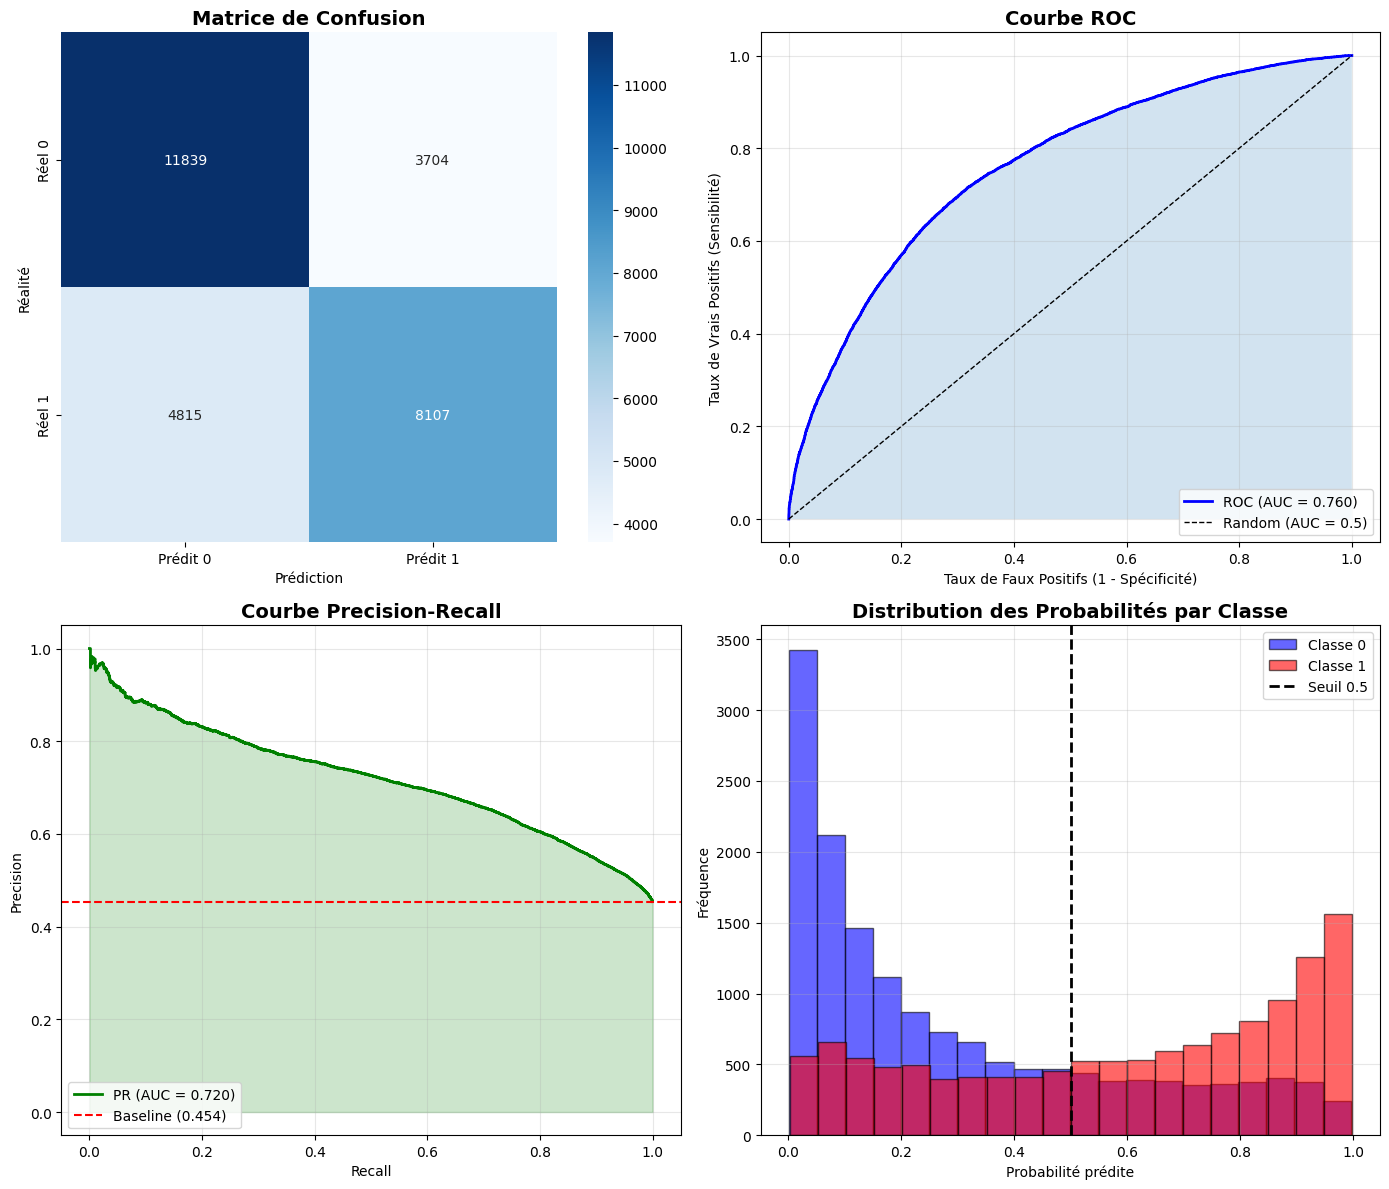

In [6]:
# =============================================================================
# CELLULE 3 : ÉVALUATION COMPLÈTE SUR LE TEST SET
# =============================================================================

# --- Évaluation sur le TEST SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TEST SET")
print("="*70)

y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Afficher les plots
plt.show()